<a href="https://colab.research.google.com/github/OberCoder/mis433/blob/main/IMDB_Visualization_SUBMIT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment - Analyzing the IMDB Top 1000 Movies

In this assignment, you will be working with this dataset of IMDB top 1000 movies.

Source: https://www.kaggle.com/harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows

In [152]:
import pandas as pd
import numpy as np

In [153]:
# Read the data file "imdb_top_1000.csv" to a dataframe named "imdb"
imdb = pd.read_csv('https://raw.githubusercontent.com/jiexunli-wwu/mis433/refs/heads/main/data/imdb_top_1000.csv', header=0)
imdb.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


In [154]:
# Describe the dataframe using the info() method.
imdb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   object 
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    object 
dtypes: float64(2), int64(1), object(13)
memory usage: 125.1+ KB


In [155]:
# List all the column names:
imdb.columns

Index(['Poster_Link', 'Series_Title', 'Released_Year', 'Certificate',
       'Runtime', 'Genre', 'IMDB_Rating', 'Overview', 'Meta_score', 'Director',
       'Star1', 'Star2', 'Star3', 'Star4', 'No_of_Votes', 'Gross'],
      dtype='object')

## Part 1: Data Manipulation

Redo the following to clean the data.

In [156]:
# Count the number of movies in each "Released_Year".
# Hint: value_counts()
imdb.Released_Year.value_counts().shape[0]

100

In [157]:
# In this dataset, there is a movie with an error in "Released_Year".
# Hint: Released_Year should be a 4-digit integer but this movie's year is not.
# Find this movie.
imdb.loc[~imdb['Released_Year'].astype(str).str.fullmatch(r'\d{4}')]

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
966,https://m.media-amazon.com/images/M/MV5BNjEzYj...,Apollo 13,PG,U,140 min,"Adventure, Drama, History",7.6,NASA must devise a strategy to return Apollo 1...,77.0,Ron Howard,Tom Hanks,Bill Paxton,Kevin Bacon,Gary Sinise,269197,"173,837,933"


In [158]:
# Correct the values for the corresponding columns ("Released_Year" and "Certificate").
# You may want to look up this movie on www.imdb.com.
# Hint: You can set value for a particular row by: df.loc[row_index, column_name] = new_value
imdb.loc[966, 'Released_Year'] = 1970

In [159]:
# Change the data type of "Released_Year" to int
imdb['Released_Year'] = imdb['Released_Year'].astype(int)

In [161]:
# Select all movies released after (>=) 2010 and with IMDB_Rating>=8.5
# Show their Series_Title, Released_Year, Certificate, and Gross.
# Sort them in descending order of "Gross"
imdb.loc[(imdb['Released_Year'] >= 2010) & (imdb['IMDB_Rating'] >= 8.5),['Series_Title','Released_Year','Certificate','Gross']].sort_values('Gross', ascending = False)

,Series_Title,Released_Year,Certificate,Gross
19,Gisaengchung,2019,A,"53,367,844"
33,Joker,2019,A,"335,451,311"
8,Inception,2010,UA,"292,576,195"
21,Interstellar,2014,UA,"188,020,017"
35,The Intouchables,2011,UA,"13,182,281"
34,Whiplash,2014,A,"13,092,000"
18,Hamilton,2020,PG-13,NaN
20,Soorarai Pottru,2020,U,NaN


In [162]:
# Does the sorting result look right to you? What's the problem?
# It's only taking into account the size of the first value, not the size of the entire string.

In [182]:
# Resolve this problem of "Gross" and convert its data type to float
# Hint: You may find this webpage useful:
# https://stackoverflow.com/questions/28986489/how-to-replace-text-in-a-column-of-a-pandas-dataframe
imdb['Gross'] = imdb['Gross'].str.replace(',','')
imdb['Gross'] = imdb['Gross'].astype(float)
imdb['Gross'].head()

,Gross
0,28341469.0
1,134966411.0
2,534858444.0
3,57300000.0
4,4360000.0


In [183]:
# Next, redo the sorting on Gross
imdb.loc[(imdb['Released_Year'] >= 2010) & (imdb['IMDB_Rating'] >= 8.5),['Series_Title','Released_Year','Certificate','Gross']].sort_values('Gross', ascending = False)
# Select all movies released after (>=) 2010 and with IMDB_Rating>=8.5
# Show their Series_Title, Released_Year, Certificate, and Gross.
# Sort them in descending order of "Gross"


,Series_Title,Released_Year,Certificate,Gross
33,Joker,2019,A,335451311.0
8,Inception,2010,UA,292576195.0
21,Interstellar,2014,UA,188020017.0
19,Gisaengchung,2019,A,53367844.0
35,The Intouchables,2011,UA,13182281.0
34,Whiplash,2014,A,13092000.0
18,Hamilton,2020,PG-13,NaN
20,Soorarai Pottru,2020,U,NaN


In [190]:
# Add a new column "Runtime_min" by removing the substring " min" in "Runtime"
# Set its data type as int
# Hint: https://stackoverflow.com/questions/36505847/substring-of-an-entire-column-in-pandas-dataframe
imdb['Runtime_Min'] = imdb['Runtime'].str.replace(" min","").astype(int)
imdb.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   int64  
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    float64
 16  Runtime_Min    1000 non-null   int64  
dtypes: float64(3), int64(3), object(11)
memory usage: 132

In [191]:
# Add a new column "Age_Years" by the expression: Current year - Released_Year
imdb['Age_Years'] = 2026 - imdb['Released_Year']
imdb.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross,Runtime_Min,Age_Years
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,28341469.0,142,32
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,134966411.0,175,54
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,534858444.0,152,18
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,57300000.0,202,52
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,4360000.0,96,69


In [192]:
# Add a new column "Decade" with values as 1980, 1990, 2000, 2010, 2020, etc.
imdb['Decade'] = imdb['Released_Year'] // 10 * 10
imdb.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross,Runtime_Min,Age_Years,Decade
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,28341469.0,142,32,1990
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,134966411.0,175,54,1970
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,534858444.0,152,18,2000
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,57300000.0,202,52,1970
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,4360000.0,96,69,1950


## Part 2: Data Summarization

Done!

## Part 3: Data Visualization

Finish Part 1 (data manipulation) before you work through this section.

In [193]:
import matplotlib.pyplot as plt
import seaborn as sns

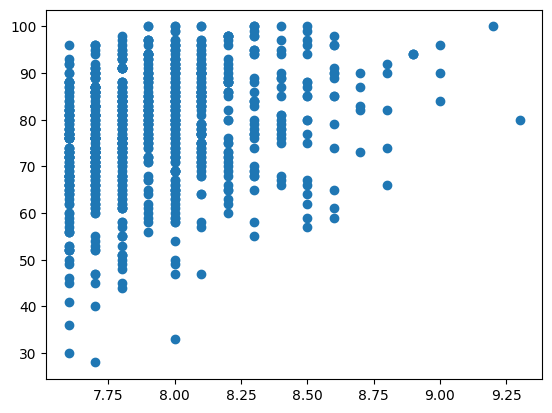

In [196]:
# Create a scatterplot of the two scores, "IMDB_Rating" and "Meta_score".
# In a sentence or two, describe what this pair of scores suggests about the movies.
plt.scatter(imdb['IMDB_Rating'],imdb['Meta_score'])
#It shows that there is a correlation between the two scoring sites and how related they are in their opinions.

<Axes: xlabel='IMDB_Rating', ylabel='Meta_score'>

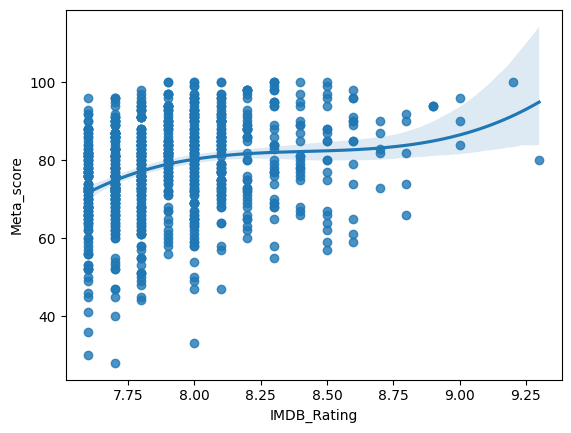

In [201]:
# Fit a trendline to show the relationship between the two scores.
# Hint: sns.regplot()
# Try a few values of the `order` argument (polynomial degree) for the trendline.
sns.regplot(x='IMDB_Rating', y='Meta_score', data=imdb, order=3)


In [207]:
# Do any data points in the scatterplot surprise you?
# Try to identify a few such movies.
better_than_9_and_75 = imdb[(imdb['Released_Year']>= 9) & (imdb['Meta_score']>=75)]
better_than_9_and_75.head()

,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross,Runtime_Min,Age_Years,Decade
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,28341469.0,142,32,1990
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,134966411.0,175,54,1970
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,534858444.0,152,18,2000
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,57300000.0,202,52,1970
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,4360000.0,96,69,1950


<Axes: xlabel='Decade', ylabel='IMDB_Rating'>

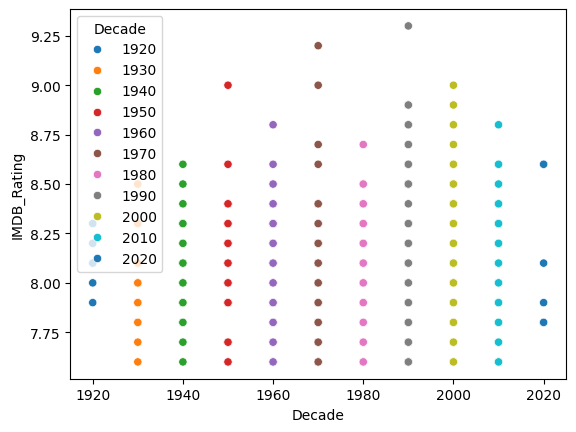

In [215]:
# In the scatterplot, use color to distinguish movies from different decades.
sns.scatterplot(x='Decade', y='IMDB_Rating', hue='Decade', data=imdb, palette='tab10')

(array([ 11.,  24.,  35.,  56.,  73.,  77.,  89., 150., 237., 248.]),
 array([1920., 1930., 1940., 1950., 1960., 1970., 1980., 1990., 2000.,
        2010., 2020.]),
 <BarContainer object of 10 artists>)

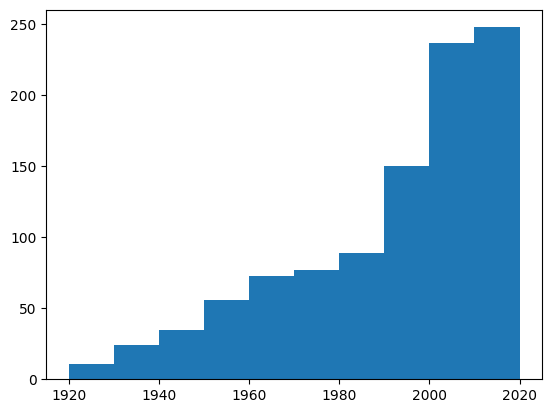

In [218]:
# Create a chart that shows how many movies fall into each decade.
plt.hist(data=imdb, x = 'Decade')

([<matplotlib.patches.Wedge at 0x7c88bf2d5950>,
 [Text(0.7971184524705537, 0.7580251794834719, ''),
  Text(-0.7038256408286814, 0.8453575972995666, ''),
  Text(-1.0372895417999695, -0.3661016340750331, ''),
  Text(-0.5086046124384279, -0.975357036272542, ''),
  Text(0.04491221374790932, -1.09908275077733, ''),
  Text(0.5389908440239357, -0.9588998227439431, ''),
  Text(0.8733897601088481, -0.6687229074414971, ''),
  Text(1.02652525662275, -0.3952795182090736, ''),
  Text(1.0817898596090019, -0.1993256121203103, ''),
  Text(1.0971297068769503, -0.07941288489972578, ''),
  Text(1.0998045851529934, -0.02073341449091957, '')],
 [Text(0.4347918831657565, 0.41346827971825734, '24.2%'),
  Text(-0.3839048949974625, 0.4611041439815817, '23.7%'),
  Text(-0.565794295527256, -0.1996918004045635, '15.0%'),
  Text(-0.2774206976936879, -0.5320129288759319, '8.9%'),
  Text(0.024497571135223262, -0.5994996822421799, '7.7%'),
  Text(0.2939950058312376, -0.5230362669512417, '7.3%'),
  Text(0.476394414604

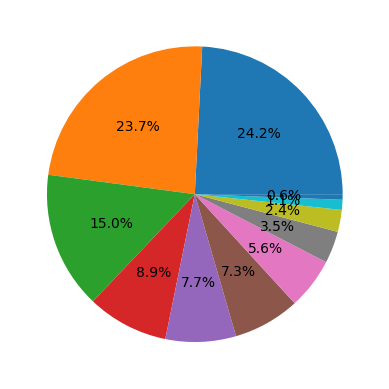

In [223]:
# Create a chart that shows the percentage of movies in each decade.
plt.pie(imdb['Decade'].value_counts(), autopct='%1.1f%%')
#plt.pie(imdb['Decade'].value_counts(), labels=imdb['Decade'].value_counts().index)

<Axes: xlabel='Director'>

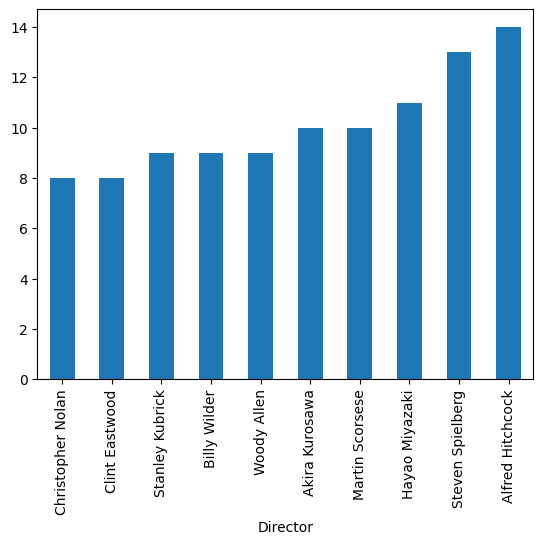

In [235]:
# Count movies by director.
# Show the top 10 directors by movie count in a bar chart.
imdb['Director'].value_counts().head(10).sort_values(ascending = True).plot(kind='bar')

<Axes: xlabel='IMDB_Rating', ylabel='Gross'>

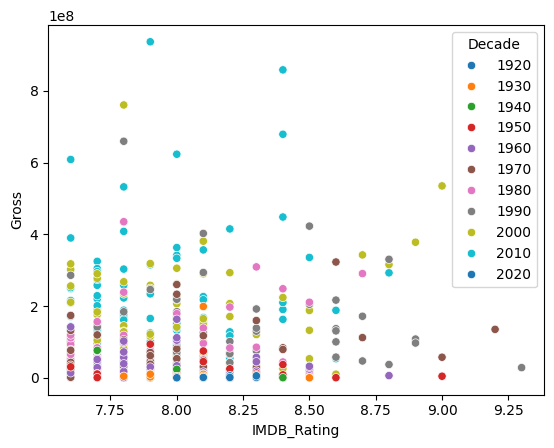

In [242]:
# Create a scatterplot of "IMDB_Rating" and "Gross".
# Use color to distinguish movies from different decades.
# Briefly interpret what the chart shows.
sns.scatterplot(data=imdb, x = 'IMDB_Rating', y = 'Gross', hue = 'Decade', palette = 'tab10')
# The 2000s and beyond grossed way more than any other decades, no matter the imdb ratings.

([<matplotlib.patches.Wedge at 0x7c88bea182d0>,
 [Text(-0.7117614948343709, 0.8386868154866522, 'Drama'),
  Text(0.7117615681547013, -0.8386867532624805, 'Non-Drama')],
 [Text(-0.38823354263692955, 0.4574655357199921, '72.4%'),
  Text(0.388233582629837, -0.45746550177953477, '27.6%')])

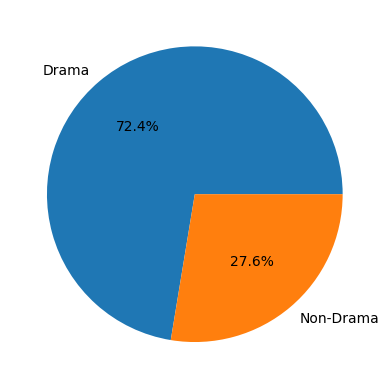

In [247]:
# Create a column named "Drama" that indicates whether a movie's Genre includes "Drama".
# Create a pie chart showing the share of drama vs. non-drama movies.
imdb['Drama'] = imdb['Genre'].str.contains('Drama')
plt.pie(imdb['Drama'].value_counts(), labels=['Drama', 'Non-Drama'], autopct='%1.1f%%')

<Axes: xlabel='Decade'>

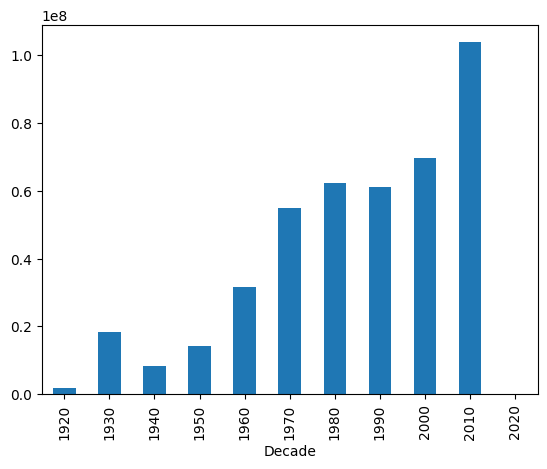

In [251]:
# Create a plot comparing Gross across decades.
imdb.groupby('Decade')['Gross'].mean().plot(kind='bar')

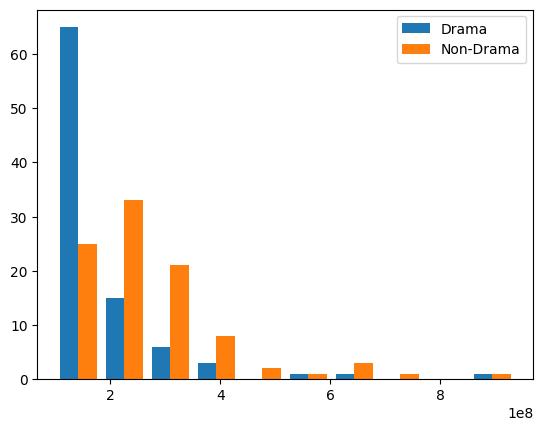

In [256]:
# For movies with Gross over $100 million:
# Create a histogram of Gross for drama vs. non-drama movies.
over100 = imdb[imdb['Gross'] >= 100000000]
plt.hist([over100.loc[over100['Drama'], 'Gross'], over100.loc[~over100['Drama'], 'Gross']], label=['Drama', 'Non-Drama'])
plt.legend()

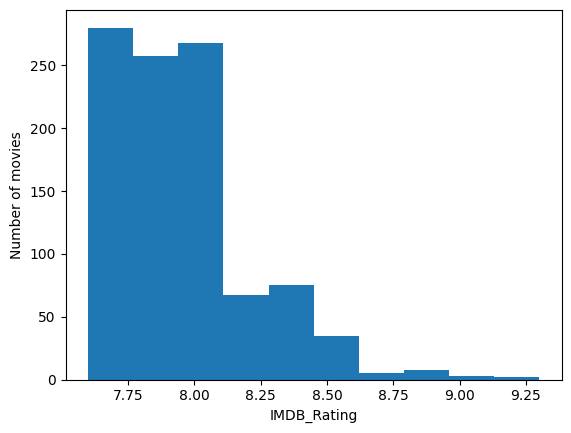

In [257]:
# Come up with two more questions about this dataset. Create one chart or figure for each.
# Question 1:
plt.hist(imdb['IMDB_Rating'], bins=10)
plt.xlabel('IMDB_Rating')
plt.ylabel('Number of movies')
plt.show()

Text(0, 0.5, 'Number of movies')

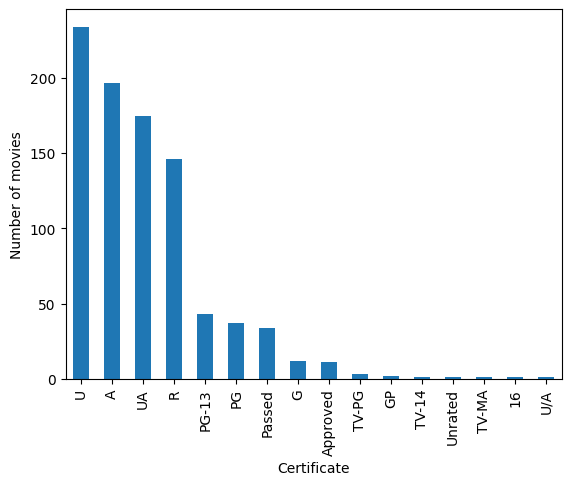

In [259]:
# Question 2:
imdb['Certificate'].value_counts().plot(kind='bar')
plt.xlabel('Certificate')
plt.ylabel('Number of movies')